# MF-X-QDMA:Multifractal Quantile Detrending Moving-average Cross-correlation Analysis

Reference: **S. Pratiher**, *Multifractal Quantile Detrending Moving-average Cross-correlation Analysis*, submitted to a journal (2026).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/MFQDMA-PaperII/blob/main/MFQDMA_PaperII.ipynb)

This single notebook regenerates **all 9 figures and all 7 data tables** of the paper.

| Part | What it does | Run time (one core) |
|---|---|---|
| 0. Setup | clones the repository (Colab), installs the requirements | < 1 min |
| 1. Recompute (optional) | re-runs the numerical experiments and overwrites `results/` | off by default; 5 min – 1 h per group, see the flags |
| 2. Figures 1–9 | draws every figure from `results/` (Fig. 1 is computed directly) | about 1 min |
| 3. Tables I–VII | generates every data table from `results/` (LaTeX rows in `tables_out/`) | seconds |
| 4. Check | compares the regenerated figures with the manuscript figures in `figures/` | seconds |
| 5. Download | zips `figures_out/`, `tables_out/` and `results/` | seconds |

By default the notebook uses the stored results in `results/`, so **Runtime → Run all** reproduces the paper in a few minutes. To regenerate the results themselves, switch on the flags in Part 1. All random seeds are fixed, so the recomputed results reproduce the stored ones.

**Data.** Synthetic pairs (binomial and 2D cascade pairs, bivariate fractional Gaussian noise, two-component ARFIMA) are generated in the code. Daily prices, the VIX and U.S. zero-coupon yields come from the CRAN package *qrmdata* (Hofert, Hornik & McNeil), cloned automatically from GitHub and read by a pure-Python parser (R is not needed).

Companion paper (univariate MFQDMA, 1D and 2D): repository `MFQDMA`.

## 0. Setup

In [1]:
#@title Setup (run first): clone the repository in Colab and install requirements
import os, sys, subprocess
GITHUB_REPO = 'https://github.com/Sawon1234/MF-X-QDMA.git'   # <- edit after upload
SUBDIR = ''          # path of this folder inside the repository, if it is not the repository root

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    root = '/content/' + GITHUB_REPO.rstrip('/').split('/')[-1].replace('.git', '')
    if not os.path.isdir(root):
        subprocess.run(['git', 'clone', '--depth', '1', GITHUB_REPO, root], check=True)
    os.chdir(os.path.join(root, SUBDIR))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
if not os.path.isdir('mfqdma'):
    raise RuntimeError('Run this notebook from the folder that contains MFQDMA_PaperII.ipynb and mfqdma/ '
                       '(in Colab: set GITHUB_REPO and SUBDIR above).')
sys.path.insert(0, os.getcwd())
try:
    from IPython.display import display, Markdown
except ImportError:                      # plain Python (no Jupyter): print instead
    display = print
    Markdown = str
import time, json, numpy as np, pandas as pd, matplotlib
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
print('working directory:', os.getcwd(), '| numpy', np.__version__, '| matplotlib', matplotlib.__version__)

working directory: /content/MF-X-QDMA | numpy 2.4.6 | matplotlib 3.10.0


## 1. Recompute the stored results (optional)

Each flag re-runs one group of experiments and overwrites the corresponding part of `results/`. Leave everything `False` to reproduce the paper from the stored results. Run times are rough estimates for a free Colab runtime (measured on one CPU core and rounded up). With `RECOMPUTE_ALL = True` the whole study takes about 1.5 h.

In [2]:
RECOMPUTE_ALL = True
# RECOMPUTE_ALL = False

In [3]:
RECOMPUTE = dict(
    offset      = False,   # results/cross_offset.json            Table I, Fig. 2           ~3 min
    bench_B     = False,   # results/cross_bench.json  B1-B4      Tables II-IV, Figs. 3-5   ~20 min
    bench_C     = False,   # results/cross_bench.json  C1-C3      Table V, Fig. 6           ~1 h
    finance_AB  = False,   # results/cross_finance.json AB        Table VI, Fig. 7          ~5 min
    finance_GH  = False,   # results/cross_finance.json G, H      Table VII, Figs. 8, 9     ~10 min
)
if RECOMPUTE_ALL:
    RECOMPUTE = {k: True for k in RECOMPUTE}
from mfqdma import experiments_paperII as E
print({k: v for k, v in RECOMPUTE.items() if v} or 'using the stored results in results/')

{'offset': True, 'bench_B': True, 'bench_C': True, 'finance_AB': True, 'finance_GH': True}


### 1a. Synthetic benchmarks

In [4]:
if RECOMPUTE['offset']:
    E.run_cross_offset()                                  # spurious cross-correlation of raw quantile residuals
if RECOMPUTE['bench_B']:
    E.run_pair_corpus()                                   # BFGN and ARFIMA pairs -> datasets/, MANIFEST.json
    E.run_cross_bench(parts=('B1', 'B2', 'B3', 'B4'))     # binomial, 2D cascade, BFGN, ARFIMA pairs
if RECOMPUTE['bench_C']:
    E.run_cross_bench(parts=('C1', 'C2', 'C3'))           # contaminated binomial and BFGN pairs

H=0.4 rho=0.0 done
H=0.4 rho=0.3 done
H=0.4 rho=0.6 done
H=0.4 rho=0.9 done
H=0.7 rho=0.0 done
H=0.7 rho=0.3 done
H=0.7 rho=0.6 done
H=0.7 rho=0.9 done
saved results/cross_offset.json
wrote 109 pairs
  B1 0.3 0.3
  B1 0.25 0.35
  B1 0.3 0.4
  B1 0.2 0.3
  B1 0.2 0.45
  B1 0.15 0.4
  B1 0.1 0.3
  B1 0.1 0.45
B1 saved 136s
  B2 A B
  B2 A C
  B2 B C
B2 saved 179s
  B3 done
B3 saved 498s
  B4 done
B4 saved 598s
  C1 x 0.0
  C1 x 0.01
  C1 x 0.02
  C1 x 0.05
  C1 x 0.1
  C1 both_indep 0.0
  C1 both_indep 0.01
  C1 both_indep 0.02
  C1 both_indep 0.05
  C1 both_indep 0.1
  C1 both_common 0.0
  C1 both_common 0.01
  C1 both_common 0.02
  C1 both_common 0.05
  C1 both_common 0.1
C1 saved 553s
  C2 0.6 0.6 0 spike
  C2 0.6 0.6 0 badtick
  C2 0.6 0.6 1 spike
  C2 0.6 0.6 1 badtick
  C2 0.4 0.8 0 spike
  C2 0.4 0.8 0 badtick
  C2 0.4 0.8 1 spike
  C2 0.4 0.8 1 badtick
C2 saved 1969s
  C3 0.6 0.6 0 spike
  C3 0.6 0.6 0 badtick
  C3 0.6 0.6 1 spike
  C3 0.6 0.6 1 badtick
  C3 0.4 0.8 0 spike
  C3 

### 1b. Financial cross-correlations

In [5]:
if RECOMPUTE['finance_AB']:
    E.run_cross_finance(parts=('AB',))                    # 16 pairs: spectra, coefficients, surrogates
if RECOMPUTE['finance_GH']:
    E.run_cross_finance(parts=('G', 'H'))                 # injected errors (16 + 29 pairs), rolling windows

  AB SP500|DJ N=7796 r=0.97
  AB DJ|NASDAQ N=7627 r=0.73
  AB SP500|FTSE N=8060 r=0.49
  AB DAX|CAC N=6302 r=0.84
  AB FTSE|DAX N=6348 r=0.76
  AB NIKKEI|HSI N=6833 r=0.47
  AB HSI|SSEC N=6132 r=0.17
  AB SSEC|CSI N=2612 r=0.98
  AB EUR_USD|GBP_USD N=4173 r=0.66
  AB EUR_USD|JPY_USD N=4173 r=0.26
  AB GOLD|EUR_USD N=4173 r=0.30
  AB GOLD|OIL_Brent N=7257 r=0.17
  AB SP500|VIX N=6552 r=-0.71
  AB UST2|UST10 N=7508 r=0.78
  AB SP500|UST10 N=7499 r=0.07
  AB BTC|SP500 N=1375 r=0.03
AB saved 119s
  G SP500|DJ
  G DJ|NASDAQ
  G SP500|FTSE
  G DAX|CAC
  G FTSE|DAX
  G NIKKEI|HSI
  G HSI|SSEC
  G SSEC|CSI
  G EUR_USD|GBP_USD
  G EUR_USD|JPY_USD
  G GOLD|EUR_USD
  G GOLD|OIL_Brent
  G SP500|VIX
  G UST2|UST10
  G SP500|UST10
  G BTC|SP500
  G DJ:AAPL
  G DJ:AXP
  G DJ:BA
  G DJ:CAT
  G DJ:CSCO
  G DJ:CVX
  G DJ:DD
  G DJ:DIS
  G DJ:GE
  G DJ:GS
  G DJ:HD
  G DJ:IBM
  G DJ:INTC
  G DJ:JNJ
  G DJ:JPM
  G DJ:KO
  G DJ:MCD
  G DJ:MMM
  G DJ:MRK
  G DJ:MSFT
  G DJ:NKE
  G DJ:PFE
  G DJ:PG
  G DJ:TR

## 2. Figures

Each cell draws one figure of the paper, shows it, and writes it to `figures_out/` as PDF and PNG. The plotting code is in `mfqdma/figures_paperII.py` (one function per figure).

In [ ]:
from mfqdma import figures_paperII as F

### Fig. 1. MF-X-QDMA on the DAX and CAC 40

MF-X-QDMA on the DAX and CAC 40 indices. (a) Profiles $Y(i)$ of daily log returns (2007--2009) with moving medians ($n=60$ days, $\theta=0$). (b) Median residuals $\epsilon_x$, $\epsilon_y$ and their product (scaled). (c) Detrended cross-correlation coefficient $\rho(n)$ for four trend functionals over 1990--2015; the dotted line is the daily Pearson coefficient.

*Source:* computed directly from the DAX and CAC 40 prices (qrmdata, cloned into `data/` on first use).

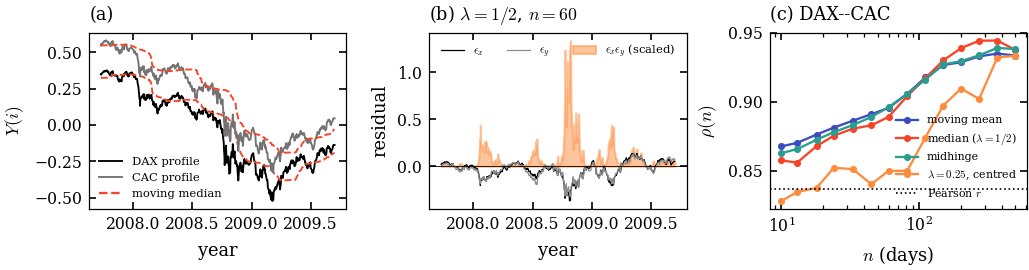

wrote /content/MF-X-QDMA/figures_out/Fig01_schematic.pdf
Fig. 1 (Fig01_schematic) done in 2 s


'Fig01_schematic'

In [7]:
F.make_figure(1)

### Fig. 2. Offset-induced spurious cross-correlation

Offset-induced spurious cross-correlation (Proposition 4). (a) $\hat\rho(n)$ of independent BFGN pairs ($H=0.7$, mean of six realizations) for raw and segment-centered quantile residuals. (b) Bias $\langle\hat\rho\rangle-\rho$ versus the true $\rho$ ($H=0.7$). (c) Attenuation $\langle\hat\rho\rangle/\rho$ of the unbiased estimators for $H=0.4$ (solid) and $H=0.7$ (dashed); colors as in (b).

*Source:* `results/cross_offset.json`.

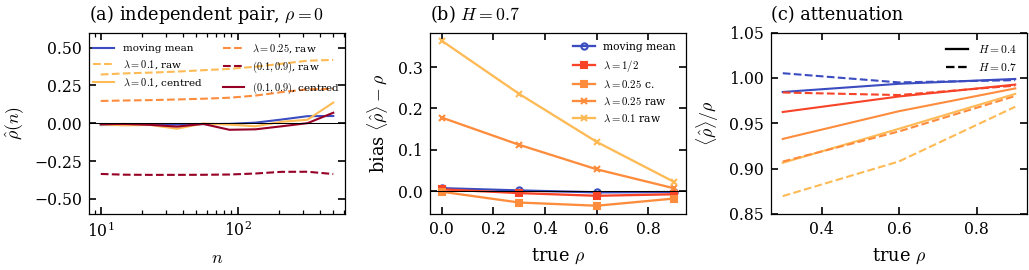

wrote /content/MF-X-QDMA/figures_out/Fig02_offset_bias.pdf
Fig. 2 (Fig02_offset_bias) done in 2 s


'Fig02_offset_bias'

In [8]:
F.make_figure(2)

### Fig. 3. Binomial-measure pairs

Binomial-measure pairs. (a) $h_{xy}(q)$ for $(p_x,p_y)=(0.2,0.45)$: exact joint-partition result, average rule (dotted), and four estimators. (b) RMSE of $h_{xy}$ against the average rule (open symbols) and against the exact result (filled) versus the gap between the two, for eight pairs. (c) Mean RMSE against the exact result over the eight pairs.

*Source:* `results/cross_bench.json` (part B1).

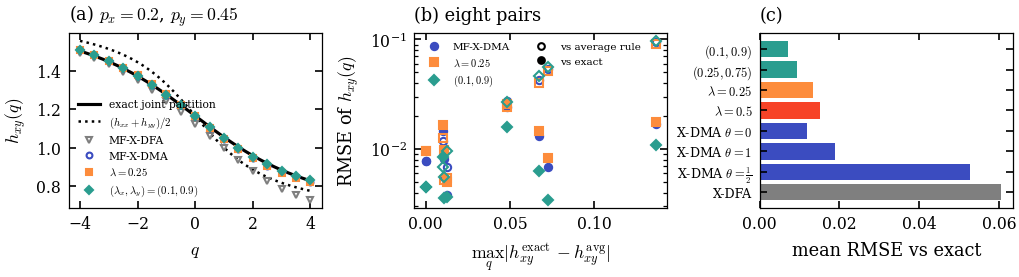

wrote /content/MF-X-QDMA/figures_out/Fig03_binomial_pairs.pdf
Fig. 3 (Fig03_binomial_pairs) done in 2 s


'Fig03_binomial_pairs'

In [9]:
F.make_figure(3)

### Fig. 4. 2D cascade pairs

2D cascade pairs. (a) Deviation of $\tau_{xy}(q)$ from the exact result for the pair B--C; the dotted line is the average rule. (b) RMSE of $\tau_{xy}$ against the exact result for three pairs and four trend functionals.

*Source:* `results/cross_bench.json` (part B2).

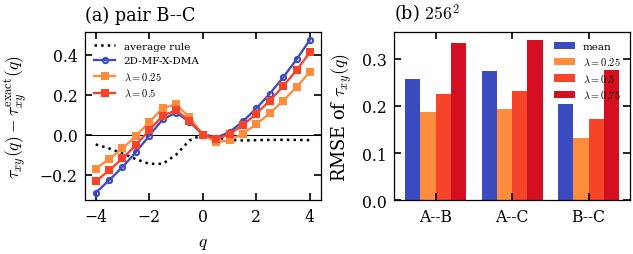

wrote /content/MF-X-QDMA/figures_out/Fig04_2d_cascade_pairs.pdf
Fig. 4 (Fig04_2d_cascade_pairs) done in 1 s


'Fig04_2d_cascade_pairs'

In [10]:
F.make_figure(4)

### Fig. 5. Monofractal pairs (BFGN, ARFIMA)

Monofractal pairs. (a) RMSE of $h_{xy}(q)$ for 75 BFGN pairs and (b) for 26 two-component ARFIMA pairs (boxes: quartiles; whiskers: 5%--95%). (c) Bias of the mean detrended coefficient for BFGN pairs with $H_{xx}=H_{yy}$ versus the nominal $\rho$.

*Source:* `results/cross_bench.json` (parts B3, B4).

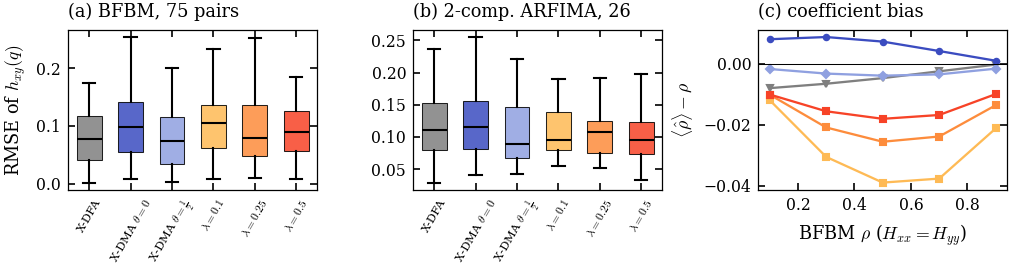

wrote /content/MF-X-QDMA/figures_out/Fig05_bfgn_arfima.pdf
Fig. 5 (Fig05_bfgn_arfima) done in 1 s


'Fig05_bfgn_arfima'

In [11]:
F.make_figure(5)

### Fig. 6. Contaminated pairs

Contaminated pairs. (a)--(c) RMSE of $h_{xy}(q)$ of the binomial pair $(0.3,0.4)$ versus the fraction $\varepsilon$ of $\pm20\sigma$ outliers, for errors in $x$ only, in both series on independent days, and in both on common days. (d) BFGN pairs: change of the detrended coefficient, mean over scales, for bad ticks (solid) and spikes (dashed) in $x$ only.

*Source:* `results/cross_bench.json` (parts C1, C3).

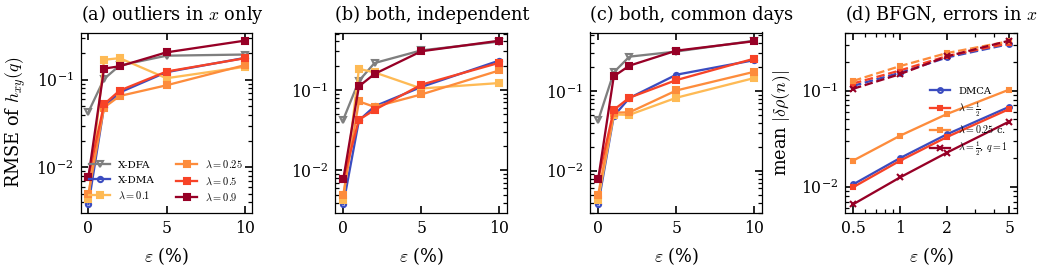

wrote /content/MF-X-QDMA/figures_out/Fig06_contamination.pdf
Fig. 6 (Fig06_contamination) done in 2 s


'Fig06_contamination'

In [12]:
F.make_figure(6)

### Fig. 7. Financial cross-correlations

Financial cross-correlations. (a) $F_{xy,q}(n)$ of DJIA--NASDAQ-100 returns (MF-X-QDMA, $\lambda=1/2$), shifted vertically; negative moments scale poorly. (b) $h_{xy}(q)$ for $q\ge0$ (thick) and $[h_{xx}+h_{yy}]/2$ (thin) for two pairs and two estimators. (c) Median-detrended coefficient $\rho_{1/2}(n)$ for six pairs; triangles mark the daily Pearson coefficient. (d) $h_{xy}(2)$ of returns and of absolute returns for the 16 pairs.

*Source:* `results/cross_finance.json` (part AB).

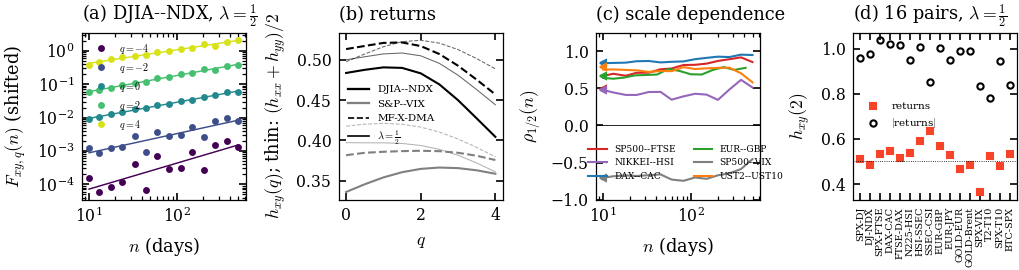

wrote /content/MF-X-QDMA/figures_out/Fig07_finance_spectra.pdf
Fig. 7 (Fig07_finance_spectra) done in 3 s


'Fig07_finance_spectra'

In [13]:
F.make_figure(7)

### Fig. 8. Sensitivity of correlation estimates to data errors

Sensitivity of correlation estimates of daily returns, distribution over the 16 financial pairs and the 29 DJIA stock--index pairs. (a), (b) $10\sigma$ and $50\sigma$ bad ticks at 0.5% of the days in one series. (c) $50\sigma$ bad ticks in both series. (d) Microstructure noise, $\eta=0.5$. Labels: Pearson $r$; DMCA; $\lambda=1/2$; midhinge; centered $\lambda=0.25$; and the $q=1$ coefficients with moving-average and median trends.

*Source:* `results/cross_finance.json` (part G).

In [ ]:
F.make_figure(8)

### Fig. 9. Time-varying correlations

Time-varying correlations with and without $50\sigma$ bad ticks at 0.5% of the days of one series. (a) S&P 500--10-year Treasury and (b) DAX--CAC: Pearson coefficient and $\rho_{1/2,q=1}(n=19)$ in four-year rolling windows. (c) Change of the cross exponents $h_{xy}(q\in[1,4])$ for $50\sigma$ bad ticks in $x$, over all 45 pairs.

*Source:* `results/cross_finance.json` (parts G, H).

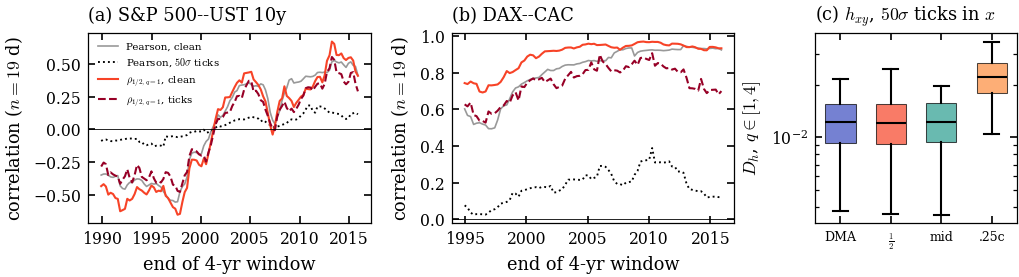

wrote /content/MF-X-QDMA/figures_out/Fig09_finance_rolling.pdf
Fig. 9 (Fig09_finance_rolling) done in 2 s


'Fig09_finance_rolling'

In [15]:
F.make_figure(9)

## 3. Tables

Every data table of the paper is generated from `results/` by `mfqdma/table_rows_paperII.py`, which writes the LaTeX body rows printed in the paper to `tables_out/`; the cells below show them as tables. Table VIII (guidelines) contains no computed numbers.

In [ ]:
from mfqdma.tables_paperII import table

### Table I

Mean detrended cross-correlation coefficient $\hat\rho$ of BFGN pairs with equal Hurst exponents $H$ and correlation $\rho$ (raw quantile residuals carry the offset of Proposition 4).

In [ ]:
display(table('I', refresh=True))

### Table II

Binomial-measure pairs ($N=2^{16}$): RMSE of $h_{xy}(q)$, $q\in[-4,4]$, against the average rule and against the exact joint-partition result.

In [18]:
display(table('II'))

,Gap,X-DMA vs average,X-DMA vs exact,X-DFA vs exact,λ=0.25,λ=0.5,"(λx,λy)=(0.1,0.9)"
"(p_x, p_y)",,,,,,,
"(0.3, 0.3)",0.000,0.008,0.008,0.045,0.010,0.012,0.005
"(0.25, 0.35)",0.011,0.006,0.008,0.047,0.010,0.012,0.004
"(0.3, 0.4)",0.013,0.007,0.004,0.043,0.005,0.008,0.004
"(0.2, 0.3)",0.010,0.012,0.015,0.057,0.017,0.018,0.008
"(0.2, 0.45)",0.072,0.054,0.007,0.060,0.008,0.011,0.003
"(0.15, 0.4)",0.067,0.043,0.013,0.064,0.015,0.016,0.006
"(0.1, 0.3)",0.049,0.027,0.024,0.079,0.026,0.025,0.016
"(0.1, 0.45)",0.137,0.094,0.017,0.088,0.018,0.018,0.011
Mean,—,0.031,0.012,0.060,0.013,0.015,0.007


### Table III

2D cascade pairs ($256\times256$): RMSE of $\tau_{xy}(q)$ against the average rule / against the exact result.

In [19]:
display(table('III'))

,Gap,Mean,λ=0.25,λ=0.5,λ=0.75
Pair,,,,,
A–B,0.085,0.293/0.256,0.226/0.187,0.264/0.226,0.367/0.334
A–C,0.051,0.281/0.274,0.205/0.194,0.242/0.233,0.344/0.339
B–C,0.147,0.219/0.204,0.168/0.133,0.195/0.173,0.280/0.276


### Table IV

Monofractal pairs: RMSE (mean ± s.d.) of $h_{xy}(q)$.

In [20]:
display(table('IV'))

,BFGN (75),ARFIMA (26)
Method,,
MF-X-DFA,0.079 ± 0.048,0.119 ± 0.053
"MF-X-DMA, θ=0",0.103 ± 0.062,0.127 ± 0.063
"MF-X-DMA, θ=1/2",0.078 ± 0.052,0.107 ± 0.050
"MF-X-DMA, θ=1",—,0.114 ± 0.045
"MF-X-QDMA, λ=0.1",0.106 ± 0.059,0.113 ± 0.043
"MF-X-QDMA, λ=0.25",0.096 ± 0.061,0.109 ± 0.045
"MF-X-QDMA, λ=0.5",0.089 ± 0.044,0.108 ± 0.054


### Table V

Contaminated binomial pair $(0.3,0.4)$: RMSE of $h_{xy}(q)$ against the exact result, mean of five replicates, $\pm20\sigma$ outliers.

In [21]:
display(table('V'))

,x only 2%,x only 5%,x only 10%,both indep. 2%,both indep. 5%,both indep. 10%,both common 2%,both common 5%,both common 10%
Method,,,,,,,,,
MF-X-DFA,0.145,0.187,0.193,0.215,0.309,0.397,0.270,0.312,0.427
MF-X-DMA,0.071,0.122,0.177,0.062,0.109,0.231,0.082,0.160,0.244
λ=0.1,0.176,0.104,0.140,0.165,0.104,0.121,0.050,0.082,0.146
λ=0.25,0.065,0.086,0.146,0.061,0.088,0.174,0.054,0.101,0.174
λ=0.5,0.075,0.124,0.175,0.056,0.116,0.217,0.082,0.137,0.255
λ=0.9,0.142,0.204,0.278,0.158,0.301,0.407,0.208,0.320,0.421


### Table VI

Sixteen daily financial pairs: period, length, Pearson coefficient, mean detrended coefficients and $h_{xy}(2)$ of returns and absolute returns.

In [22]:
display(table('VI'))

,Period,N,r,ρ,ρ_1/2,"ρ_1/2,q=1",h_xy(2) X-DMA,h_xy(2) λ=1/2,h_xy(2) |r| X-DMA,h_xy(2) |r| λ=1/2
Pair,,,,,,,,,,
S&P 500–DJIA,1985–15,7796,+0.97,+0.96,+0.95,+0.96,0.51,0.51,0.87,0.96
DJIA–NDX,1985–15,7627,+0.73,+0.73,+0.73,+0.80,0.52,0.48,0.88,0.97
S&P 500–FTSE,1984–15,8060,+0.49,+0.82,+0.82,+0.83,0.54,0.53,0.89,1.04
DAX–CAC,1990–15,6302,+0.84,+0.90,+0.90,+0.92,0.55,0.55,0.88,1.02
FTSE–DAX,1990–15,6348,+0.76,+0.81,+0.80,+0.83,0.54,0.51,0.89,1.02
Nikkei–HSI,1987–15,6833,+0.47,+0.44,+0.43,+0.47,0.53,0.54,0.84,0.95
HSI–SSEC,1990–15,6132,+0.17,+0.31,+0.30,+0.39,0.57,0.59,0.91,1.01
SSEC–CSI 300,2005–15,2612,+0.98,+0.98,+0.98,+0.99,0.67,0.64,0.89,0.85
EUR–GBP,2000–15,4173,+0.66,+0.72,+0.71,+0.82,0.55,0.57,0.91,1.01


### Table VII

Sensitivity of correlation estimates of daily returns to injected data errors: median over pairs of the mean absolute change of the coefficient over scales ($\times10^3$).

In [23]:
display(table('VII'))

,Pairs,r,DMCA ρ,ρ_1/2,ρ_mid,ρ_0.25 c.,q=1 DMA,q=1 median,wins
Error,,,,,,,,,
"Bad ticks in x, 10σ",16 pairs,165,11.4,10.7,11.5,21.6,9.6,9.1,13/16
,29 stocks,187,15.5,13.7,15.0,25.0,12.0,11.5,27/29
"Bad ticks in x, 50σ",16 pairs,459,148.4,143.6,151.6,210.4,79.4,77.2,15/16
,29 stocks,517,173.9,165.7,175.0,227.6,98.5,96.1,29/29
"Bad ticks in both, 10σ",16 pairs,288,25.0,22.9,24.8,44.0,18.2,18.9,12/16
,29 stocks,326,31.4,28.9,30.8,53.2,24.4,23.4,29/29
"Bad ticks in both, 50σ",16 pairs,546,264.0,250.7,263.4,343.9,164.6,155.0,15/16
,29 stocks,628,286.1,269.1,283.1,361.8,182.1,171.5,29/29
Return outliers in x,16 pairs,108,122.3,132.0,125.0,144.9,107.3,108.6,10/16


## 4. Check against the manuscript

Compares each regenerated figure (`figures_out/`) with the figure in the submitted manuscript (`figures/`). "identical" means pixel-identical PNG files, "close" that fewer than 1% of the pixels differ noticeably. The reference figures were drawn with Matplotlib 3.11 and its bundled DejaVu/Computer Modern fonts; with another Matplotlib version, small rendering differences (anti-aliasing, glyph placement) can make figures with identical data show up as "DIFFERS". The numbers themselves are checked by the tables in Part 3, which can be compared with the paper directly.

In [24]:
from mfqdma.verify import compare_figures
display(compare_figures())

,mean_abs_diff,frac_pixels_changed,status
figure,,,
Fig01_schematic,18.101,0.11238,DIFFERS
Fig02_offset_bias,20.503,0.13277,DIFFERS
Fig03_binomial_pairs,18.649,0.11253,DIFFERS
Fig04_2d_cascade_pairs,14.685,0.09868,DIFFERS
Fig05_bfgn_arfima,16.349,0.09550,DIFFERS
Fig06_contamination,15.487,0.09933,DIFFERS
Fig07_finance_spectra,22.539,0.13439,DIFFERS
Fig08_finance_coefficient_robustness,26.319,0.15018,DIFFERS
Fig09_finance_rolling,23.080,0.13846,DIFFERS


## 5. Download the outputs

In [25]:
#@title Collect all regenerated figures, tables and results in one zip file
import shutil
from mfqdma import paths
stage = paths.REPO / '_export'
shutil.rmtree(stage, ignore_errors=True)
for d in ('figures_out', 'tables_out', 'results'):
    if (paths.REPO / d).is_dir():
        shutil.copytree(paths.REPO / d, stage / d)
archive = shutil.make_archive(str(paths.REPO / 'MFQDMA_PaperII_outputs'), 'zip', stage)
shutil.rmtree(stage)
print('wrote', archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)

wrote /content/MF-X-QDMA/MFQDMA_PaperII_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>